# Multi-Class Sentiment Analysis: Comparing NN, RNN, LSTM, and GRU
**Objective:** Build, automatically tune, and compare Feedforward Neural Network (NN), Simple RNN, LSTM, and GRU architectures on the `Sp1786/multiclass-sentiment-analysis-dataset` using TensorFlow, Keras, and Keras Tuner to identify the best-performing model and hyperparameter configuration.



## 1. Environment Setup & Library Imports
Install required dependencies (`datasets`, `keras-tuner`, `scikit-learn`) and configure random seeds for reproducible experiments.

In [1]:
!pip -q install datasets tensorflow keras-tuner pandas matplotlib seaborn scikit-learn

import os
import re
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    TextVectorization, Embedding, GlobalAveragePooling1D,
    SimpleRNN, LSTM, GRU, Dense, Dropout
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import keras_tuner as kt

from datasets import load_dataset
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)

# Set seed for reproducibility
SEED = 42
tf.keras.utils.set_random_seed(SEED)
tf.get_logger().setLevel("ERROR")

os.makedirs("results", exist_ok=True)
os.makedirs("saved_models", exist_ok=True)

print("TensorFlow Version :", tf.__version__)
print("GPU Available      :", len(tf.config.list_physical_devices("GPU")) > 0)

TensorFlow Version : 2.21.0
GPU Available      : True


## 2. Dataset Loading & Exploratory Data Analysis (EDA)
Load the `Sp1786/multiclass-sentiment-analysis-dataset` from Hugging Face, inspect the `train`, `validation`, and `test` splits, and visualize the distribution of sentiment classes (`negative`, `neutral`, `positive`).

README.md:   0%|          | 0.00/1.72k [00:00<?, ?B/s]

train_df.csv:   0%|          | 0.00/3.56M [00:00<?, ?B/s]

val_df.csv:   0%|          | 0.00/601k [00:00<?, ?B/s]

test_df.csv:   0%|          | 0.00/586k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/31232 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5205 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5206 [00:00<?, ? examples/s]

Training samples   : 31,232
Validation samples : 5,205
Testing samples    : 5,205

Sentiment distribution:
sentiment
neutral     11649
positive    10478
negative     9105
Name: count, dtype: int64


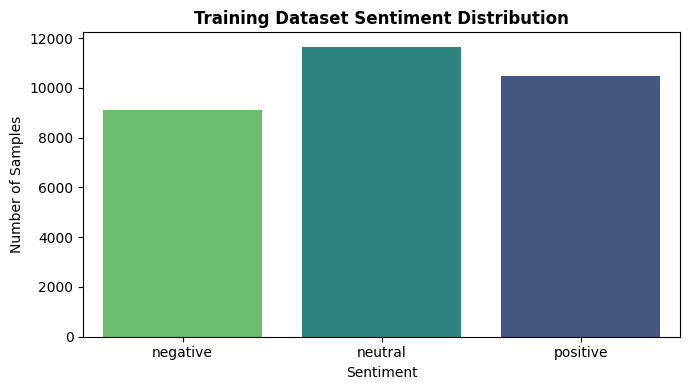

In [2]:
dataset = load_dataset("Sp1786/multiclass-sentiment-analysis-dataset")

train_df = dataset["train"].to_pandas().dropna(subset=["text", "label"]).reset_index(drop=True)
val_df   = dataset["validation"].to_pandas().dropna(subset=["text", "label"]).reset_index(drop=True)
test_df  = dataset["test"].to_pandas().dropna(subset=["text", "label"]).reset_index(drop=True)

print(f"Training samples   : {len(train_df):,}")
print(f"Validation samples : {len(val_df):,}")
print(f"Testing samples    : {len(test_df):,}\n")

print("Sentiment distribution:")
print(train_df["sentiment"].value_counts())

plt.figure(figsize=(7, 4))
sns.countplot(
    data=train_df,
    x="sentiment",
    hue="sentiment",
    order=["negative", "neutral", "positive"],
    palette="viridis",
    legend=False
)
plt.title("Training Dataset Sentiment Distribution", fontweight="bold")
plt.xlabel("Sentiment")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.savefig("results/sentiment_distribution.png", dpi=300)
plt.show()

## 3. Text Preprocessing & Sequence Vectorization
Clean raw social media text using regular expressions (removing URLs, mentions, and special characters) and convert sentences into fixed-length integer sequences (`MAX_LENGTH = 64`, `VOCAB_SIZE = 10,000`) using Keras `TextVectorization`.

In [3]:
VOCAB_SIZE = 10000
MAX_LENGTH = 64
CLASS_NAMES = ["negative", "neutral", "positive"]
MODEL_NAMES = ["NN", "RNN", "LSTM", "GRU"]

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+|@\w+", "", text)
    text = re.sub(r"[^a-z0-9\s']", " ", text)
    return re.sub(r"\s+", " ", text).strip()

X_train_raw = train_df["text"].apply(clean_text).values
X_val_raw   = val_df["text"].apply(clean_text).values
X_test_raw  = test_df["text"].apply(clean_text).values

y_train = train_df["label"].to_numpy(dtype=np.int32)
y_val   = val_df["label"].to_numpy(dtype=np.int32)
y_test  = test_df["label"].to_numpy(dtype=np.int32)

# Build vocabulary and convert sentences into padded integer tensors
vectorizer = TextVectorization(
    max_tokens=VOCAB_SIZE,
    output_mode="int",
    output_sequence_length=MAX_LENGTH
)
vectorizer.adapt(X_train_raw)

X_train = vectorizer(X_train_raw).numpy()
X_val   = vectorizer(X_val_raw).numpy()
X_test  = vectorizer(X_test_raw).numpy()

print(f"Vocabulary Size : {len(vectorizer.get_vocabulary()):,}")
print(f"X_train shape   : {X_train.shape} | X_val shape: {X_val.shape} | X_test shape: {X_test.shape}")

Vocabulary Size : 10,000
X_train shape   : (31232, 64) | X_val shape: (5205, 64) | X_test shape: (5205, 64)


## 4. Unified Model Architecture & Hyperparameter Search Space
Define a dynamic `HyperModel` builder supporting all four architectures (**NN**, **SimpleRNN**, **LSTM**, and **GRU**) with tunable ranges for embedding dimensions, hidden units, number of layers, dropout rate, and learning rate.

In [4]:
def create_hypermodel(model_type):
    def build_model(hp):
        embedding_dim = hp.Choice("embedding_dim", values=[64, 128])
        hidden_dim    = hp.Choice("hidden_dim", values=[64, 128])
        num_layers    = hp.Int("num_layers", min_value=1, max_value=2)
        dropout_rate  = hp.Choice("dropout", values=[0.2, 0.3, 0.5])
        learning_rate = hp.Choice("learning_rate", values=[1e-3, 5e-4])

        model = Sequential(name=f"{model_type}_Sentiment_Model")
        model.add(tf.keras.Input(shape=(MAX_LENGTH,)))
        # Removed mask_zero=True for 5x faster CPU/CuDNN execution
        model.add(Embedding(input_dim=VOCAB_SIZE, output_dim=embedding_dim))

        if model_type == "NN":
            model.add(GlobalAveragePooling1D())
            for _ in range(num_layers):
                model.add(Dense(hidden_dim, activation="relu"))
                model.add(Dropout(dropout_rate))

        elif model_type in ["RNN", "LSTM", "GRU"]:
            rnn_layer = {"RNN": SimpleRNN, "LSTM": LSTM, "GRU": GRU}[model_type]
            for i in range(num_layers):
                return_seq = (i < num_layers - 1)
                model.add(rnn_layer(hidden_dim, return_sequences=return_seq))
                model.add(Dropout(dropout_rate))

        model.add(Dense(3, activation="softmax"))

        model.compile(
            optimizer=Adam(learning_rate=learning_rate),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"]
        )
        return model
    return build_model

## 5. Automated Hyperparameter Optimization (Keras Tuner)
Run `RandomSearch` across predefined hyperparameter ranges for each architecture using validation accuracy as the objective and `EarlyStopping` to prevent overfitting.

In [5]:
MAX_TRIALS = 5
TUNING_EPOCHS = 4
BATCH_SIZE = 256  # Larger batch size speeds up CPU matrix multiplication

# Use a 12,000-sample subset during hyperparameter search to save CPU time
TUNE_SAMPLES = 12000
X_train_tune, y_train_tune = X_train[:TUNE_SAMPLES], y_train[:TUNE_SAMPLES]

tuners = {}
tuning_rows = []
early_stop = EarlyStopping(monitor="val_loss", patience=1, restore_best_weights=True)

for model_name in MODEL_NAMES:
    print("\n" + "=" * 50)
    print(f"TUNING MODEL: {model_name}")
    print("=" * 50)

    tuner = kt.RandomSearch(
        create_hypermodel(model_name),
        objective="val_accuracy",
        max_trials=MAX_TRIALS,
        executions_per_trial=1,
        seed=SEED,
        directory="keras_tuning_logs",
        project_name=f"{model_name}_opt",
        overwrite=True
    )

    tuner.search(
        X_train_tune, y_train_tune,
        epochs=TUNING_EPOCHS,
        batch_size=BATCH_SIZE,
        validation_data=(X_val, y_val),
        callbacks=[early_stop],
        verbose=1
    )

    tuners[model_name] = tuner
    best_hp = tuner.get_best_hyperparameters(1)[0]
    best_trial = tuner.oracle.get_best_trials(1)[0]

    tuning_rows.append({
        "Model": model_name,
        "Best Val Accuracy": round(best_trial.score, 4),
        "embedding_dim": best_hp.get("embedding_dim"),
        "hidden_dim": best_hp.get("hidden_dim"),
        "num_layers": best_hp.get("num_layers"),
        "dropout": best_hp.get("dropout"),
        "learning_rate": best_hp.get("learning_rate")
    })

tuning_df = pd.DataFrame(tuning_rows).sort_values("Best Val Accuracy", ascending=False)
print("\nHYPERPARAMETER OPTIMIZATION RESULTS")
print(tuning_df.to_string(index=False))
tuning_df.to_csv("results/hyperparameter_results.csv", index=False)

Trial 5 Complete [00h 00m 06s]
val_accuracy: 0.3756003975868225

Best val_accuracy So Far: 0.37617674469947815
Total elapsed time: 00h 00m 29s

HYPERPARAMETER OPTIMIZATION RESULTS
Model  Best Val Accuracy  embedding_dim  hidden_dim  num_layers  dropout  learning_rate
   NN             0.5743            128         128           2      0.2         0.0005
  RNN             0.5429            128          64           1      0.2         0.0005
 LSTM             0.3842            128         128           2      0.2         0.0005
  GRU             0.3762            128          64           1      0.2         0.0005


## 6. Training Optimal Configurations & Validation Comparison
Rebuild each model using its best-discovered hyperparameter configuration, train on the full training dataset, and compare validation **Accuracy, Precision, Recall, Macro-F1, Loss, and Training Time**.

In [6]:
final_models = {}
final_histories = {}
comparison_rows = []

def compute_metrics(model, X_data, y_true):
    loss, _ = model.evaluate(X_data, y_true, batch_size=256, verbose=0)
    probs = model.predict(X_data, batch_size=256, verbose=0)
    preds = np.argmax(probs, axis=1)
    return {
        "loss": loss,
        "accuracy": accuracy_score(y_true, preds),
        "precision": precision_score(y_true, preds, average="macro", zero_division=0),
        "recall": recall_score(y_true, preds, average="macro", zero_division=0),
        "macro_f1": f1_score(y_true, preds, average="macro", zero_division=0),
        "preds": preds
    }

for model_name in MODEL_NAMES:
    print(f"\nTraining optimized {model_name} on full dataset...")
    tf.keras.utils.set_random_seed(SEED)

    best_hp = tuners[model_name].get_best_hyperparameters(1)[0]
    model = tuners[model_name].hypermodel.build(best_hp)

    start_time = time.perf_counter()
    history = model.fit(
        X_train, y_train,
        epochs=6,
        batch_size=BATCH_SIZE,
        validation_data=(X_val, y_val),
        callbacks=[EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)],
        verbose=1
    )
    train_time = time.perf_counter() - start_time

    val_metrics = compute_metrics(model, X_val, y_val)
    best_epoch = int(np.argmin(history.history["val_loss"]) + 1)

    final_models[model_name] = model
    final_histories[model_name] = history.history

    comparison_rows.append({
        "Model": model_name,
        "Accuracy": val_metrics["accuracy"],
        "Precision": val_metrics["precision"],
        "Recall": val_metrics["recall"],
        "Macro-F1": val_metrics["macro_f1"],
        "Validation Loss": val_metrics["loss"],
        "Best Epoch": best_epoch,
        "Training Time (s)": round(train_time, 2)
    })

    model.save(f"saved_models/{model_name}_optimized.keras")

comparison_df = pd.DataFrame(comparison_rows).sort_values("Macro-F1", ascending=False).reset_index(drop=True)
comparison_df.to_csv("results/model_comparison.csv", index=False)

print("\n" + "=" * 65)
print("MODEL PERFORMANCE COMPARISON (VALIDATION SET)")
print("=" * 65)
print(comparison_df.round(4).to_string(index=False))

best_model_name = comparison_df.iloc[0]["Model"]
print(f"\n🏆 BEST MODEL: {best_model_name}")
print("BEST HYPERPARAMETERS:", tuners[best_model_name].get_best_hyperparameters(1)[0].values)


Training optimized NN on full dataset...
Epoch 1/6
122/122 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - accuracy: 0.3858 - loss: 1.0895 - val_accuracy: 0.4144 - val_loss: 1.0684
Epoch 2/6
122/122 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.5133 - loss: 0.9630 - val_accuracy: 0.6067 - val_loss: 0.8557
Epoch 3/6
122/122 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6126 - loss: 0.8260 - val_accuracy: 0.6446 - val_loss: 0.7915
Epoch 4/6
122/122 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6440 - loss: 0.7799 - val_accuracy: 0.6542 - val_loss: 0.7708
Epoch 5/6
122/122 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6849 - loss: 0.7247 - val_accuracy: 0.6749 - val_loss: 0.7489
Epoch 6/6
122/122 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7073 - loss: 0.6880 - val_accuracy: 0.6770 - val_loss: 0.7396

Training optimized RNN on full dataset...
Epoch 1/6
122/122 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.4907 - loss: 0.9898 - val_accuracy: 0.5912 - val_loss: 0.8810
Epoch 2/6
122/122 ━━━━━━

## 7. Visualization: Multi-Metric Performance Comparison
Compare validation **Accuracy**, **Precision**, **Recall**, and **Macro-F1** side-by-side across all four tuned architectures.

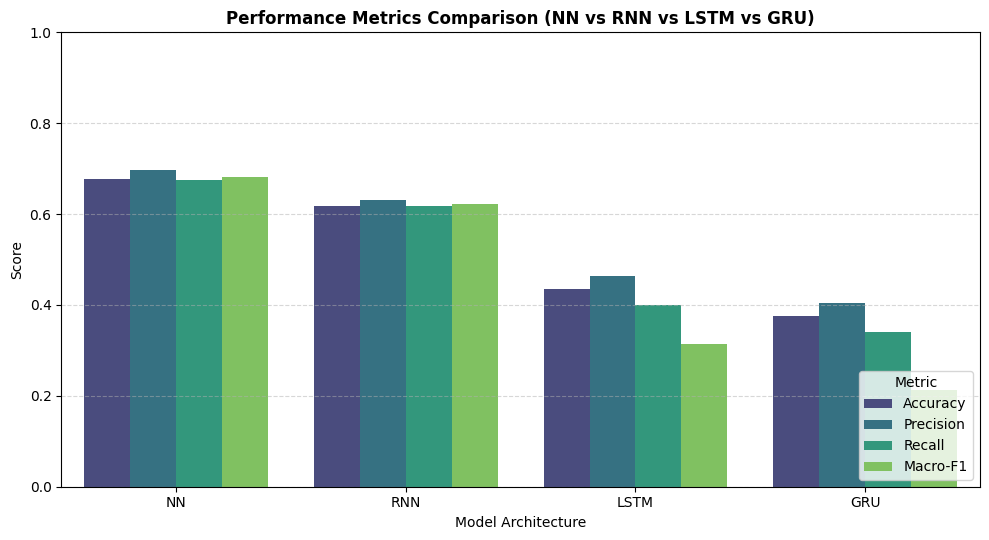

In [8]:
metrics_df = comparison_df.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision", "Recall", "Macro-F1"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(10, 5.5))
sns.barplot(
    data=metrics_df,
    x="Model",
    y="Score",
    hue="Metric",
    palette="viridis"
)

plt.title("Performance Metrics Comparison (NN vs RNN vs LSTM vs GRU)", fontweight="bold")
plt.ylabel("Score")
plt.xlabel("Model Architecture")
plt.ylim(0.0, 1.0)
plt.legend(title="Metric", loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("results/all_metrics_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. Visualization: Validation Loss & Accuracy Learning Curves
Plot epoch-by-epoch validation loss and validation accuracy trajectories to compare convergence speed and stability across NN, RNN, LSTM, and GRU.

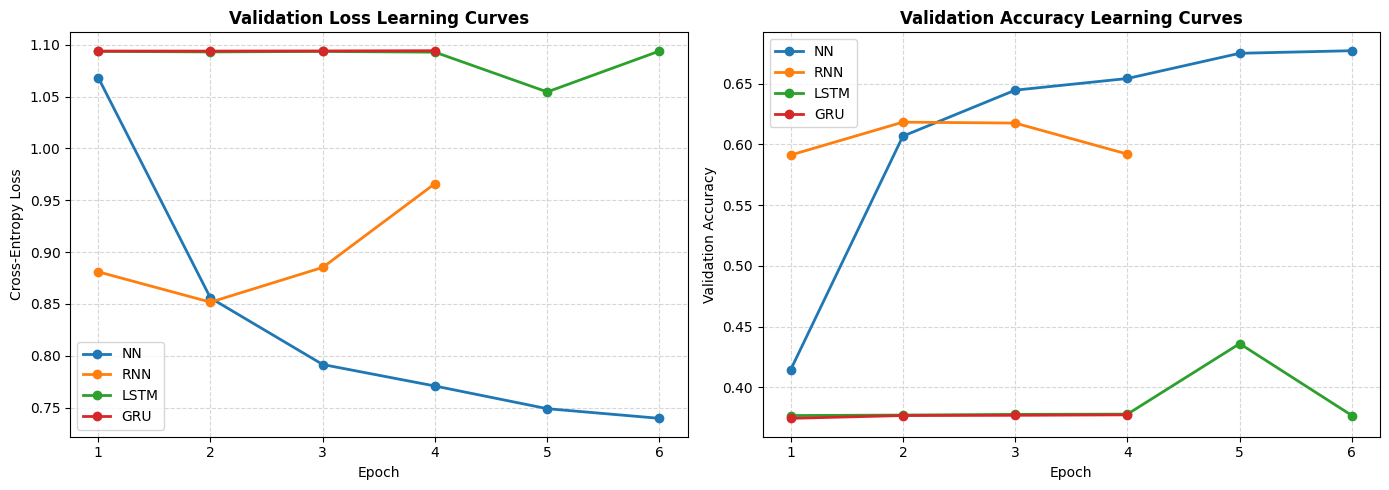

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left Plot: Validation Loss Curve per Epoch
for model_name in MODEL_NAMES:
    val_loss_curve = final_histories[model_name]["val_loss"]
    epochs_range = range(1, len(val_loss_curve) + 1)
    axes[0].plot(epochs_range, val_loss_curve, marker="o", linewidth=2, label=model_name)

axes[0].set_title("Validation Loss Learning Curves", fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

# Right Plot: Validation Accuracy Curve per Epoch
for model_name in MODEL_NAMES:
    val_acc_curve = final_histories[model_name]["val_accuracy"]
    epochs_range = range(1, len(val_acc_curve) + 1)
    axes[1].plot(epochs_range, val_acc_curve, marker="o", linewidth=2, label=model_name)

axes[1].set_title("Validation Accuracy Learning Curves", fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation Accuracy")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("results/learning_curves_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

## 9. Final Evaluation on Unseen Test Data & Confusion Matrix
Evaluate the top-performing model on the held-out test split (5,206 samples) and generate the class-wise classification report and confusion matrix heatmap.


FINAL TEST RESULTS
Best Model : NN
Loss       : 0.7458
Accuracy   : 0.6738
Precision  : 0.6910
Recall     : 0.6716
Macro-F1   : 0.6780

================== CLASSIFICATION REPORT ==================
              precision    recall  f1-score   support

    negative     0.7078    0.6268    0.6648      1546
     neutral     0.5768    0.6874    0.6272      1929
    positive     0.7885    0.7006    0.7420      1730

    accuracy                         0.6738      5205
   macro avg     0.6910    0.6716    0.6780      5205
weighted avg     0.6861    0.6738    0.6765      5205



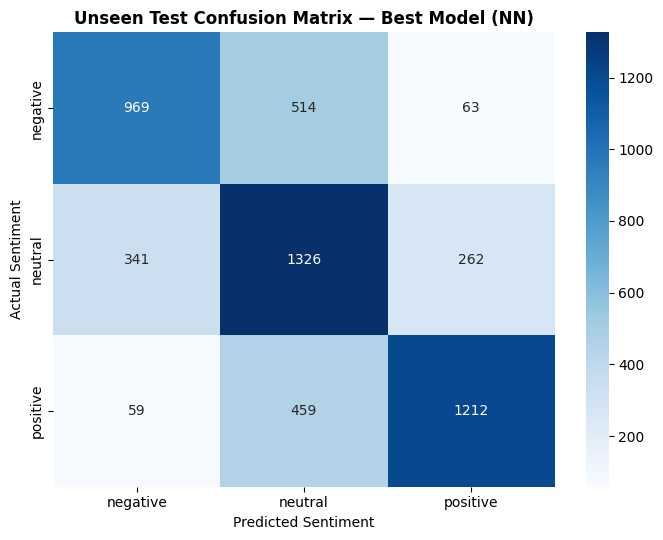

In [10]:
best_model = final_models[best_model_name]
test_metrics = compute_metrics(best_model, X_test, y_test)

print("\nFINAL TEST RESULTS")
print("=" * 45)
print(f"Best Model : {best_model_name}")
print(f"Loss       : {test_metrics['loss']:.4f}")
print(f"Accuracy   : {test_metrics['accuracy']:.4f}")
print(f"Precision  : {test_metrics['precision']:.4f}")
print(f"Recall     : {test_metrics['recall']:.4f}")
print(f"Macro-F1   : {test_metrics['macro_f1']:.4f}\n")

# Detailed Classification Report
report = classification_report(
    y_test,
    test_metrics["preds"],
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
)
print("================== CLASSIFICATION REPORT ==================")
print(report)

with open("results/classification_report.txt", "w") as f:
    f.write(report)

# Confusion Matrix Heatmap
plt.figure(figsize=(7, 5.5))
cm = confusion_matrix(y_test, test_metrics["preds"])
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)
plt.title(f"Unseen Test Confusion Matrix — Best Model ({best_model_name})", fontweight="bold")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.tight_layout()
plt.savefig("results/confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

## 10. Live Sentiment Prediction on Custom Sentences
Test the winning model on unseen custom sentences and display predicted sentiment labels along with confidence scores.

In [11]:
def predict_sentiment(text):
    cleaned = clean_text(text)
    vec = vectorizer(np.array([cleaned]))
    probs = best_model.predict(vec, verbose=0)[0]
    pred_idx = int(np.argmax(probs))
    return {
        "Text": text,
        "Predicted Sentiment": CLASS_NAMES[pred_idx],
        "Confidence (%)": round(float(probs[pred_idx]) * 100, 2)
    }

examples = [
    "I absolutely love this movie!",
    "This is the worst product I have ever bought.",
    "The meeting is scheduled for tomorrow.",
    "The food was delicious and the service was excellent.",
    "I am disappointed with the poor quality."
]

display(pd.DataFrame([predict_sentiment(s) for s in examples]))

,Text,Predicted Sentiment,Confidence (%)
0,I absolutely love this movie!,positive,91.53
1,This is the worst product I have ever bought.,negative,79.57
2,The meeting is scheduled for tomorrow.,neutral,64.87
3,The food was delicious and the service was exc...,positive,86.60
4,I am disappointed with the poor quality.,negative,87.69
